
### __This section compares model results across different training set sizes.__

- Each experiment saves its metrics in a `results.json` file.

- Here, we read all result files from the `models` folder, extract the most important metrics and compare how the training set size affects model performance.

In [7]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

# models_dir = Path("../model_for_mel/models")
models_dir = Path("../model_for_mfcc/models")
results = []

for result_path in models_dir.glob("*/results.json"):
    with open(result_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # skip mini evaluation runs, it's only for testing codes
    if data.get("use_mini_evaluation") is True:
        continue

    # keep only the metrics needed for comparing different training set sizes
    results.append({
        "train_split_name": data.get("train_split_name"),
        "best_epoch": data.get("best_epoch"),
        "best_validation_loss": data.get("best_validation_loss"),
        "best_validation_accuracy": data.get("best_validation_accuracy"),
        "test_accuracy": data.get("test_accuracy"),
    })

# sort results by training set size
results = sorted(results, key=lambda r: int(r["train_split_name"].replace("train_", "")))

# print the table header
print(
    f"{'train_size':<12}"
    f"{'epoch':<8}"
    f"{'val_loss':<12}"
    f"{'val_acc':<12}"
    f"{'test_acc':<12}"
)

for r in results:
    print(
        f"{r['train_split_name']:<12}"
        f"{r['best_epoch']:<8}"
        f"{r['best_validation_loss']:<12.4f}"
        f"{r['best_validation_accuracy']:<12.4f}"
        f"{r['test_accuracy']:<12.4f}"
    )

train_size  epoch   val_loss    val_acc     test_acc    
train_25    6       1.3419      0.6196      0.6173      
train_50    8       1.3240      0.6227      0.6190      
train_75    5       1.3288      0.6217      0.6220      
train_100   8       1.3227      0.6229      0.6230      


- To visualize the comparison, we plot the metrics against training set size.

__What we want to see__
- Accuracy should generally increase as more training data is used.

- Validation loss should generally decrease if the model benefits from more data.

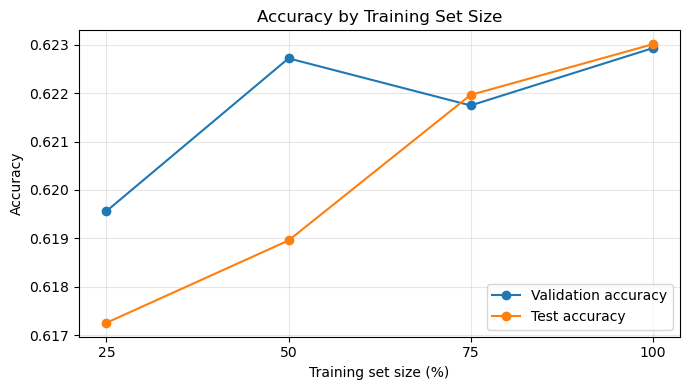

In [8]:
# first plot: validation accuracy and test accuracy by training size
train_sizes = [int(r["train_split_name"].replace("train_", ""))for r in results]
validation_losses = [r["best_validation_loss"]for r in results]
validation_accuracies = [r["best_validation_accuracy"]for r in results]
test_accuracies = [r["test_accuracy"]for r in results]

plt.figure(figsize=(7, 4))

plt.plot(train_sizes, validation_accuracies, marker="o", label="Validation accuracy")

plt.plot(train_sizes, test_accuracies, marker="o", label="Test accuracy")

plt.xlabel("Training set size (%)")
plt.ylabel("Accuracy")
plt.title("Accuracy by Training Set Size")

plt.xticks(train_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# plt.savefig("Accuracy_by_Size_Mel.png", dpi=300, bbox_inches="tight")
plt.savefig("Accuracy_by_Size_Mfcc.png", dpi=300, bbox_inches="tight")
plt.show()

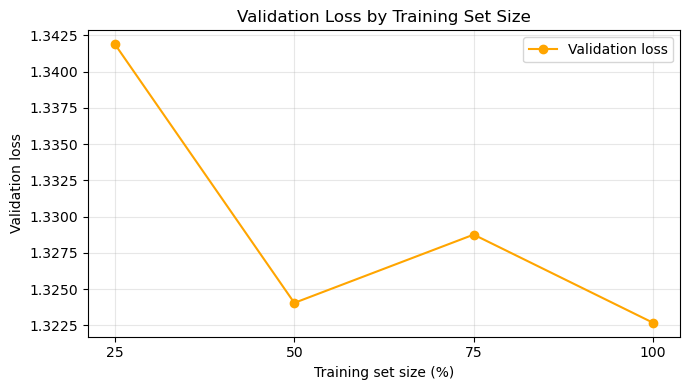

In [9]:
# second plot: validation loss by training size
plt.figure(figsize=(7, 4))

plt.plot(train_sizes, validation_losses, marker="o", color="orange", label="Validation loss")

plt.xlabel("Training set size (%)")
plt.ylabel("Validation loss")
plt.title("Validation Loss by Training Set Size")

plt.xticks(train_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# plt.savefig("Validation_Loss_by_Size_Mel.png", dpi=300, bbox_inches="tight")
plt.savefig("Validation_Loss_by_Size_Mfcc.png", dpi=300, bbox_inches="tight")
plt.show()